# ASL Citizen SLR — Green Computing, Model 4/5: TimeSformer (Transformer, Heavy)

**Course:** CSE 407 — Green Computing
**Paper:** *Quantifying the Carbon Cost of Accuracy: An Energy-Aware Comparison of CNN and Transformer Architectures for Word-Level Sign Language Recognition*
**This notebook is 4 of 5** in the model family requested by faculty feedback on the proposal.

## Changelog / where this fits

### Relationship to notebook 3 (small ViViT)
This is the **heavy** member of the Transformer pair from faculty suggestion 1 (small ViViT vs.
TimeSformer). It uses the official **Kinetics-400-pretrained TimeSformer-base** checkpoint
(`facebook/timesformer-base-finetuned-k400`, via 🤗 `transformers`) rather than a hand-built
model, since — unlike "small ViViT" — TimeSformer has a real, publicly released checkpoint at
this size.

**This is not the same architecture as notebook 3 at a bigger size.** TimeSformer uses *divided
space-time attention*: each block attends over time, then over space, within one shared stack
of layers (Bertasius et al., *Is Space-Time Attention All You Need for Video Understanding?*,
ICML 2021). Notebook 3's ViViT-Lite uses the *Factorised Encoder* design: a fully separate
spatial encoder, then a fully separate temporal encoder. Both are legitimate, named designs from
the ViViT/video-Transformer literature — they're genuinely different attention patterns, which
is exactly why they're the light/heavy pair here rather than the same model scaled up.

### Two real (not cosmetic) differences from every other notebook so far
1. **Frame count changes from 16 to 8.** The cache stores 16-frame clips (unchanged since
   notebook 1). TimeSformer-base-K400's published usage samples 8 frames, and its pretrained
   temporal position embeddings are sized for that. Rather than reinitializing those pretrained
   temporal weights to fit 16 frames, this notebook uniformly subsamples the cached 16 frames
   down to 8 (`CONFIG.TIMESFORMER_NUM_FRAMES`, Section 4) to keep the pretrained temporal
   knowledge intact. **State this in the paper** — this model sees less temporal context per
   clip than notebooks 1-3, which is a real methodological difference, not just a backbone swap.
2. **Normalization is read from TimeSformer's own processor, not assumed.** Notebooks 1-3 use
   standard ImageNet mean/std for their (ImageNet-pretrained) backbones. This notebook instead
   loads `AutoImageProcessor.from_pretrained(...)` and reads its actual `image_mean`/`image_std`
   at runtime (Section 4) rather than guessing that Kinetics-pretrained stats match ImageNet's —
   they aren't guaranteed to, so this avoids silently feeding the pretrained model
   out-of-distribution inputs.

### Same caveats as notebook 3, carried forward
- **FLOPs figure is a lower bound**, likely an even larger undercount than notebook 3's — `thop`
  still only hooks `Conv`/`Linear` layers, and TimeSformer's divided attention does strictly
  more attention compute per layer (space *and* time) than ViViT-Lite's factorised design.
- **Training hyperparameters are unchanged** from notebooks 1-3 (`CONFIG.BATCH_SIZE=8`, same LR,
  same epoch budget) to preserve the controlled comparison, even though this is the heaviest
  backbone in the family so far. If it OOMs on the assigned Kaggle GPU, record that as a result
  (which batch size does fit) rather than quietly shrinking it and moving on — a heavier
  Transformer needing more memory headroom than the lighter models is itself part of this
  paper's cost story.
- **`TOP_K_CLASSES=100`, `GRID_CARBON_INTENSITY_KG_PER_KWH=0.475`, `EXPECTED_INFERENCE_VOLUME=100_000`**
  unchanged from notebooks 1-3.
- **Not resumable across sessions** — run start-to-finish in one session so the `codecarbon`
  energy total is valid.
- Scaffolding for the paper, not the paper — produces `green_metrics_timesformer_base_transformer_heavy.json`,
  matching the earlier notebooks' schema plus two model-specific fields (`frame_count_used`,
  `gflops_is_lower_bound`).

## 1. Setup & Imports

In [1]:
# --- One-time install of green-computing / profiling / model packages not preinstalled on Kaggle ---
import subprocess
import sys

for _pkg, _import_name in [("codecarbon", "codecarbon"), ("thop", "thop"), ("transformers", "transformers")]:
    try:
        __import__(_import_name)
    except ImportError:
        print(f"Installing {_pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=False)

import csv
import json
import math
import random
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import precision_recall_fscore_support
from transformers import TimesformerModel, AutoImageProcessor

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

print(f"Torch: {torch.__version__}")
import transformers as _transformers_pkg
print(f"transformers: {_transformers_pkg.__version__}")
print(f"Device: {DEVICE}")
print("Assumes Kaggle's internet toggle is ON, same as notebooks 1-3 -- needed to "
      "download the pretrained TimeSformer checkpoint and its processor config.")


Installing codecarbon ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 396.9/396.9 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.0/71.0 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 81.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 101.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 104.4 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
sigstore 4.3.0 requires cryptography<49,>=42, but you have cryptography 50.0.0 which is incompatible.
pydrive2 1.21.3 requires cryptography<44, but you have cryptography 50.0.0 which is incompatible.
pyopenssl 24.2.1 requires cryptography<44,>=41.0.5, but you have cryptography 50.0.0 which is incompatible.


Installing thop ...
Torch: 2.10.0+cu128
transformers: 5.0.0
Device: cuda
Assumes Kaggle's internet toggle is ON, same as notebooks 1-3 -- needed to download the pretrained TimeSformer checkpoint and its processor config.


## 1b. Hardware & Software Environment

Captured directly so energy/carbon figures in this notebook can be sanity-checked and reproduced (paper review Major Issue #4).

In [2]:
# --- Hardware / software environment capture (Green-Computing review fix #4) ---
# CodeCarbon's energy figures are software-based power *estimates*; a reader cannot judge
# their reliability, or reproduce this run, without knowing what hardware and software stack
# produced them. Captured once per run and carried into the model card / multi-seed report.
import platform

HARDWARE_INFO = {
    "torch_version": torch.__version__,
    "cuda_version_torch_built_with": torch.version.cuda,
    "cudnn_version": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "cpu_count_logical": __import__("os").cpu_count(),
    "gpu_available": torch.cuda.is_available(),
}

if torch.cuda.is_available():
    _gpu_props = torch.cuda.get_device_properties(0)
    HARDWARE_INFO.update({
        "gpu_name": torch.cuda.get_device_name(0),
        "gpu_count": torch.cuda.device_count(),
        "gpu_total_memory_gb": round(_gpu_props.total_memory / (1024**3), 2),
        "gpu_capability": f"{_gpu_props.major}.{_gpu_props.minor}",
    })
else:
    HARDWARE_INFO.update({"gpu_name": None, "gpu_count": 0, "gpu_total_memory_gb": None, "gpu_capability": None})

# Best-effort CPU/RAM info via psutil if available (Kaggle usually has it); degrade gracefully.
try:
    import psutil
    HARDWARE_INFO["ram_total_gb"] = round(psutil.virtual_memory().total / (1024**3), 2)
except ImportError:
    HARDWARE_INFO["ram_total_gb"] = None

print("Hardware / software environment for this run:")
for k, v in HARDWARE_INFO.items():
    print(f"  {k}: {v}")
print()
print("NOTE: this is the actual execution environment of THIS run. The grid carbon-intensity "
      "constant in Section 10 (Google Cloud us-central1, cited) is a fixed methodological "
      "assumption applied uniformly across the 5-model family (paper Section 3.4/6) -- it is "
      "NOT necessarily the grid this specific session's hardware is physically attached to. "
      "If this notebook is run on infrastructure known to sit in a specific region, replace "
      "CONFIG.GRID_CARBON_INTENSITY_KG_PER_KWH with that region's cited figure and relabel "
      "reported CO2e figures accordingly -- see the paper review's Major Issue #5.")


Hardware / software environment for this run:
  torch_version: 2.10.0+cu128
  cuda_version_torch_built_with: 12.8
  cudnn_version: 91002
  python_version: 3.12.13
  platform: Linux-6.12.90+-x86_64-with-glibc2.35
  cpu_count_logical: 4
  gpu_available: True
  gpu_name: Tesla T4
  gpu_count: 2
  gpu_total_memory_gb: 14.56
  gpu_capability: 7.5
  ram_total_gb: 31.35

NOTE: this is the actual execution environment of THIS run. The grid carbon-intensity constant in Section 10 (Google Cloud us-central1, cited) is a fixed methodological assumption applied uniformly across the 5-model family (paper Section 3.4/6) -- it is NOT necessarily the grid this specific session's hardware is physically attached to. If this notebook is run on infrastructure known to sit in a specific region, replace CONFIG.GRID_CARBON_INTENSITY_KG_PER_KWH with that region's cited figure and relabel reported CO2e figures accordingly -- see the paper review's Major Issue #5.


## 2. Green-Computing & Model Configuration

In [3]:
class CONFIG:
    WORK_DIR = Path("/kaggle/working")

    # ---- update these to match your mounted paths -- identical to notebooks 1-3 ----
    CACHE_DIRS = [
        Path("/kaggle/input/notebooks/aniruddha2022/asl-shared-cache-building-id00/feature_cache_shard_0"),
        Path("/kaggle/input/notebooks/redoanmozumder/asl-shared-cache-building-id02/feature_cache_shard_2"),
        Path("/kaggle/input/notebooks/pranaysahaps/asl-shared-cache-building-id01/feature_cache_shard_1"),
    ]
    SPLITS_DIR = Path("/kaggle/input/datasets/pranaysahaps/asl-citizen/splits")

    MODEL_TAG = "timesformer_base_transformer_heavy"
    CHECKPOINT_DIR = WORK_DIR / f"checkpoints_{MODEL_TAG}"
    OUTPUT_DIR = WORK_DIR / f"green_report_{MODEL_TAG}"

    # ---- Kept IDENTICAL to notebooks 1-3 where applicable -- see their Section 2
    # notes on why these must not vary per-model. ----
    TOP_K_CLASSES = 100
    APPEARANCE_STREAM_IDX = 0
    IMAGE_SIZE = 224

    # ---- Cached clips are 16 frames (FRAME_COUNT, unchanged from notebooks 1-3 --
    # that's a property of the shared cache, not of this model). TimeSformer-base-K400
    # itself was pretrained expecting 8-frame clips (its published usage example samples
    # 8 frames), and its temporal position embeddings are sized for that. Rather than
    # reinitializing those pretrained temporal embeddings for a mismatched frame count,
    # this notebook uniformly subsamples the cached 16 frames down to 8 (see Section 4)
    # -- a deliberate deviation from notebooks 1-3's full 16-frame input, made to keep
    # TimeSformer's pretrained temporal weights intact. Note this explicitly in the
    # paper: it's a real difference in temporal context seen by this model vs. the
    # others, not just a backbone swap. ----
    FRAME_COUNT = 16                 # cache's native frame count -- unchanged
    TIMESFORMER_NUM_FRAMES = 8       # frames actually fed to TimeSformer, after subsampling

    # ---- Model: TimeSformer, Transformer family, heavier member (vs. notebook 3's
    # small ViViT). Uses the official Kinetics-400-pretrained checkpoint -- divided
    # space-time attention within shared blocks (Bertasius et al. 2021), a genuinely
    # different attention pattern from notebook 3's factorised-encoder ViViT. ----
    TIMESFORMER_CHECKPOINT = "facebook/timesformer-base-finetuned-k400"
    # 12 transformer layers in the base checkpoint; freeze all but the last N (+ final
    # layernorm), same partial-freeze principle as every other notebook in the family.
    TIMESFORMER_UNFROZEN_LAYERS = 2

    # ---- Training -- identical to notebooks 1-3 (same rationale: preserve the
    # controlled comparison). Batch size is also unchanged even though TimeSformer-base
    # is the heaviest backbone in the family so far -- if this OOMs on the Kaggle GPU,
    # that is itself a data point worth reporting (see Section 5 note), not something
    # to silently shrink away. ----
    BATCH_SIZE = 8
    NUM_WORKERS = 2
    LR = 1e-4
    WEIGHT_DECAY = 3e-4
    GRAD_CLIP_NORM = 0.5
    LABEL_SMOOTHING = 0.1

    EPOCHS_FULL = 30
    MIN_EPOCHS_BEFORE_STOPPING = 15
    EARLY_STOPPING_PATIENCE = 6

    ACCURACY_GATE_THRESHOLD = 0.60  # soft reference point, not a hard requirement
    # The 60% figure above is author-chosen, not externally justified (paper review Minor
    # Issue #7). Rather than rest deployment conclusions on one unjustified line, the
    # deployment-readiness discussion (Section 10b) is reported parametrically across this
    # range so the reader can see whether the recommendation is threshold-sensitive.
    ACCURACY_GATE_THRESHOLDS_FOR_SENSITIVITY = [0.50, 0.60, 0.70]

    SEED = 42
    # Repeated-seed runs for statistical validity (paper review Major Issue #2: every
    # comparative claim in the original single-run version rests on n=1 per model).
    # SEED remains the default/primary seed (used by the single detailed run in Sections
    # 7-9 with full training curves); SEEDS is the full set repeated in the new Section 9b
    # for mean +/- SD reporting. Kept short (3) so the added compute stays tractable --
    # extend if compute budget allows.
    SEEDS = [42, 123, 2024]
    DEVICE = DEVICE

    # ---- Green computing accounting -- identical constants to notebooks 1-3 ----
    GRID_CARBON_INTENSITY_KG_PER_KWH = 0.41272  # Google Cloud us-central1, 2024 (412.72 gCO2eq/kWh) -- see notebook 1, Section 2, for the full citation/caveat note
    EXPECTED_INFERENCE_VOLUME = 100_000

    # Sensitivity range for the lifecycle-carbon-per-inference metric (paper review
    # Recommended fix: the 100,000-inference figure is not sensitivity-tested in the
    # original submission). eta_life is reported at each of these volumes, not just the
    # single point assumption above, so the ranking in Section 10 can be checked for
    # stability across plausible deployment scales.
    DEPLOYMENT_VOLUME_SENSITIVITY = [10_000, 100_000, 1_000_000]
    INFERENCE_PROFILING_PASSES = 3


def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(CONFIG.SEED)
CONFIG.CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CONFIG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Model tag: {CONFIG.MODEL_TAG}")
print(f"Device: {CONFIG.DEVICE}")
print(f"Top-K classes: {CONFIG.TOP_K_CLASSES}")
print(f"Cached frames: {CONFIG.FRAME_COUNT} -> subsampled to {CONFIG.TIMESFORMER_NUM_FRAMES} for TimeSformer")


Model tag: timesformer_base_transformer_heavy
Device: cuda
Top-K classes: 100
Cached frames: 16 -> subsampled to 8 for TimeSformer


## 3. Build the Manifest & Apply the Top-K Class Filter

In [4]:
cache_index = {}
for shard_dir in CONFIG.CACHE_DIRS:
    assert shard_dir.exists(), f"Cache shard not found: {shard_dir} -- update CONFIG.CACHE_DIRS"
    for f in shard_dir.glob("*.npz"):
        cache_index[f.stem] = f
print(f"Total cached .npz files across {len(CONFIG.CACHE_DIRS)} shards: {len(cache_index)}")

split_files = {
    "train": CONFIG.SPLITS_DIR / "train.csv",
    "val": CONFIG.SPLITS_DIR / "val.csv",
    "test": CONFIG.SPLITS_DIR / "test.csv",
}
rows, all_glosses = [], set()
for subset, csv_path in split_files.items():
    assert csv_path.exists(), f"Missing split file: {csv_path}"
    with open(csv_path, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            video_id = Path(row["Video file"]).stem
            gloss = row["Gloss"]
            all_glosses.add(gloss)
            if video_id in cache_index:
                rows.append((video_id, gloss, subset))

class_list_full = sorted(all_glosses)
class_to_idx_full = {g: i for i, g in enumerate(class_list_full)}

nslt_data_full = {}
for video_id, gloss, subset in rows:
    nslt_data_full[video_id] = {"action": [class_to_idx_full[gloss], 0, 0], "subset": subset}

print(f"Cached rows matched against splits: {len(rows)}")
print(f"Full ASL Citizen vocabulary present in cache: {len(class_list_full)} classes")

# --- top-K filter, identical remap logic to the Capstone notebooks' PILOT_MODE cell ---
class_video_counts = Counter(v["action"][0] for v in nslt_data_full.values())
top_k_old_indices = [c for c, _ in class_video_counts.most_common(CONFIG.TOP_K_CLASSES)]
top_k_old_indices_set = set(top_k_old_indices)
old_to_new_idx = {old_idx: new_idx for new_idx, old_idx in enumerate(top_k_old_indices)}

nslt_data = {
    vid: {"action": [old_to_new_idx[meta["action"][0]], 0, 0], "subset": meta["subset"]}
    for vid, meta in nslt_data_full.items()
    if meta["action"][0] in top_k_old_indices_set
}
class_list = {old_to_new_idx[old]: class_list_full[old] for old in top_k_old_indices}
NUM_CLASSES = len(class_list)

subset_counts = Counter(v["subset"] for v in nslt_data.values())
print(f"\nTop-{CONFIG.TOP_K_CLASSES} filter applied -- NUM_CLASSES: {NUM_CLASSES}")
print(f"Videos remaining: {len(nslt_data)} across splits {dict(subset_counts)}")

per_class_counts = Counter(v["action"][0] for v in nslt_data.values())
print(f"Videos/class (post-filter, all splits combined): "
      f"min={min(per_class_counts.values())} median={int(np.median(list(per_class_counts.values())))} "
      f"max={max(per_class_counts.values())}")


Total cached .npz files across 3 shards: 63550
Cached rows matched against splits: 63550
Full ASL Citizen vocabulary present in cache: 2731 classes

Top-100 filter applied -- NUM_CLASSES: 100
Videos remaining: 3200 across splits {'train': 1434, 'val': 357, 'test': 1409}
Videos/class (post-filter, all splits combined): min=32 median=32 max=32


### 3b. Signer-Independence Check

Verifies whether the pre-built train/val/test split is signer-disjoint (paper review Major Issue #1) before any model is trained on it.

In [5]:
# --- Signer-independence check for the train/val/test split (paper review Major Issue #1) ---
# ASL Citizen has 52 distinct signers. If the same signer appears in both train and test,
# accuracy is inflated by signer-specific visual cues (clothing, background, hand-shape
# idiosyncrasies) rather than sign semantics -- a leakage risk the original submission never
# checked. This cell re-reads the split CSVs looking for a participant/signer identifier and
# reports whether the pre-built splits in CONFIG.SPLITS_DIR are signer-disjoint.

POSSIBLE_SIGNER_COLUMNS = [
    "Participant ID", "ParticipantID", "Participant", "Signer ID", "SignerID",
    "Signer", "signer_id", "participant_id",
]

video_to_signer = {}
signer_column_used = None
for subset, csv_path in split_files.items():
    with open(csv_path, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        fieldnames = reader.fieldnames or []
        if signer_column_used is None:
            signer_column_used = next((c for c in POSSIBLE_SIGNER_COLUMNS if c in fieldnames), None)
        for row in reader:
            video_id = Path(row["Video file"]).stem
            if signer_column_used is not None:
                video_to_signer[video_id] = row[signer_column_used]
            else:
                # Fallback: ASL Citizen video filenames are prefixed with the participant ID
                # (e.g. "<participant_id>-<gloss>-<take>"). This is a heuristic, not a
                # guaranteed-correct parse -- flagged explicitly below.
                video_to_signer[video_id] = video_id.split("-")[0]

signers_by_subset = {s: set() for s in split_files}
for video_id, gloss, subset in rows:
    if video_id in video_to_signer:
        signers_by_subset[subset].add(video_to_signer[video_id])

overlap_train_val = signers_by_subset["train"] & signers_by_subset["val"]
overlap_train_test = signers_by_subset["train"] & signers_by_subset["test"]
overlap_val_test = signers_by_subset["val"] & signers_by_subset["test"]

SIGNER_INDEPENDENCE_REPORT = {
    "signer_column_found": signer_column_used,
    "signer_id_source": "csv_column" if signer_column_used is not None else "filename_prefix_heuristic",
    "n_signers_train": len(signers_by_subset["train"]),
    "n_signers_val": len(signers_by_subset["val"]),
    "n_signers_test": len(signers_by_subset["test"]),
    "n_signers_overlap_train_val": len(overlap_train_val),
    "n_signers_overlap_train_test": len(overlap_train_test),
    "n_signers_overlap_val_test": len(overlap_val_test),
    "is_signer_disjoint": (len(overlap_train_val) == 0 and len(overlap_train_test) == 0
                            and len(overlap_val_test) == 0),
}

print("Signer-independence check (paper review Major Issue #1):")
for k, v in SIGNER_INDEPENDENCE_REPORT.items():
    print(f"  {k}: {v}")

if signer_column_used is None:
    print("\n[WARNING] No explicit signer/participant column found in the split CSVs -- the "
          "signer IDs above were inferred from the video-filename prefix, which is a heuristic, "
          "NOT a verified signer identifier. Treat this report as provisional and confirm "
          "against ASL Citizen's official participant metadata before relying on it.")

if not SIGNER_INDEPENDENCE_REPORT["is_signer_disjoint"]:
    print("\n[MAJOR CAVEAT] Signer overlap detected across splits. Every accuracy figure in "
          "this notebook may be inflated by signer-specific cues rather than sign semantics. "
          "This should be disclosed alongside any accuracy number reported from this run, and "
          "a signer-disjoint re-split is required before the comparative claims in the paper "
          "can be trusted.")
else:
    print("\nSplits are signer-disjoint for every video where a signer ID could be resolved -- "
          "no cross-split signer leakage detected under this check.")


Signer-independence check (paper review Major Issue #1):
  signer_column_found: Participant ID
  signer_id_source: csv_column
  n_signers_train: 35
  n_signers_val: 5
  n_signers_test: 11
  n_signers_overlap_train_val: 0
  n_signers_overlap_train_test: 0
  n_signers_overlap_val_test: 0
  is_signer_disjoint: True

Splits are signer-disjoint for every video where a signer ID could be resolved -- no cross-split signer leakage detected under this check.


## 4. Dataset & DataLoaders — Appearance Stream (Subsampled to 8 Frames)

Same cache and manifest as notebooks 1-3. What's different: frames are subsampled from the
cached 16 down to `CONFIG.TIMESFORMER_NUM_FRAMES` (8), and normalized using TimeSformer's own
processor stats — pulled at runtime, not assumed to match the ImageNet stats notebooks 1-3
used.

In [6]:
# Pull TimeSformer's own normalization constants from its processor config rather than
# assuming ImageNet stats (notebooks 1-3's CNN/ViT-Tiny backbones use ImageNet
# normalization; there's no guarantee a Kinetics-pretrained video model uses the same
# constants, so read them directly instead of hardcoding a guess).
_timesformer_processor = AutoImageProcessor.from_pretrained(CONFIG.TIMESFORMER_CHECKPOINT)
TIMESFORMER_MEAN = torch.tensor(_timesformer_processor.image_mean).view(1, 3, 1, 1)
TIMESFORMER_STD = torch.tensor(_timesformer_processor.image_std).view(1, 3, 1, 1)
print(f"TimeSformer processor normalization -- mean: {_timesformer_processor.image_mean}, "
      f"std: {_timesformer_processor.image_std}")

_subsample_idx = np.linspace(0, CONFIG.FRAME_COUNT - 1, CONFIG.TIMESFORMER_NUM_FRAMES).round().astype(int)
print(f"Subsampling cached frame indices: {_subsample_idx.tolist()}")


def frames_to_tensor(frames_uint8):
    """(T_cached, H, W, 3) uint8 -> (TIMESFORMER_NUM_FRAMES, 3, IMAGE_SIZE, IMAGE_SIZE)
    float, subsampled and normalized with TimeSformer's own processor stats."""
    frames_uint8 = frames_uint8[_subsample_idx]                 # (T_sub, H, W, 3)
    t = torch.from_numpy(frames_uint8).float() / 255.0
    t = t.permute(0, 3, 1, 2)                                    # (T_sub, 3, H, W)
    t = F.interpolate(t, size=(CONFIG.IMAGE_SIZE, CONFIG.IMAGE_SIZE),
                       mode="bilinear", align_corners=False)
    t = (t - TIMESFORMER_MEAN) / TIMESFORMER_STD
    return t


class WLASLAppearanceDataset(Dataset):
    """Same cache and manifest as notebooks 1-3 -- only frames_to_tensor differs
    (subsampling + TimeSformer-specific normalization instead of the full 16 frames
    with ImageNet normalization)."""

    def __init__(self, nslt_data, cache_index, subset):
        self.cache_index = cache_index
        self.samples = [
            (vid, meta["action"][0])
            for vid, meta in nslt_data.items()
            if meta["subset"] == subset and vid in self.cache_index
        ]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        video_id, class_idx = self.samples[idx]
        data = np.load(self.cache_index[video_id])

        appearance_raw = data["appearance"]  # (T_cached, num_streams, H, W, 3) uint8
        frames = appearance_raw[:, CONFIG.APPEARANCE_STREAM_IDX]  # (T_cached, H, W, 3)
        frames_t = frames_to_tensor(frames)

        label = torch.tensor(class_idx, dtype=torch.long)
        return frames_t, label


train_dataset = WLASLAppearanceDataset(nslt_data, cache_index, "train")
val_dataset = WLASLAppearanceDataset(nslt_data, cache_index, "val")
test_dataset = WLASLAppearanceDataset(nslt_data, cache_index, "test")

print(f"Train samples (cached): {len(train_dataset)}")
print(f"Val samples (cached):   {len(val_dataset)}")
print(f"Test samples (cached):  {len(test_dataset)}")

# --- WeightedRandomSampler for class imbalance -- unchanged from notebooks 1-3 ---
train_class_counts = Counter(class_idx for _, class_idx in train_dataset.samples)
train_sample_weights = [1.0 / train_class_counts[c] for _, c in train_dataset.samples]
train_sampler = WeightedRandomSampler(train_sample_weights, num_samples=len(train_sample_weights),
                                       replacement=True)

train_loader = DataLoader(train_dataset, batch_size=CONFIG.BATCH_SIZE, sampler=train_sampler,
                           num_workers=CONFIG.NUM_WORKERS, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG.BATCH_SIZE, shuffle=False,
                         num_workers=CONFIG.NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=CONFIG.BATCH_SIZE, shuffle=False,
                          num_workers=CONFIG.NUM_WORKERS)

sample_frames, sample_labels = next(iter(train_loader))
print("Batch frames shape:", sample_frames.shape)   # (B, TIMESFORMER_NUM_FRAMES, 3, IMAGE_SIZE, IMAGE_SIZE)
print("Batch labels shape:", sample_labels.shape)


preprocessor_config.json:   0%|          | 0.00/412 [00:00<?, ?B/s]

The image processor of type `VideoMAEImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 
`use_fast` is set to `True` but the image processor class does not have a fast version.  Falling back to the slow version.


TimeSformer processor normalization -- mean: [0.45, 0.45, 0.45], std: [0.225, 0.225, 0.225]
Subsampling cached frame indices: [0, 2, 4, 6, 9, 11, 13, 15]
Train samples (cached): 1434
Val samples (cached):   357
Test samples (cached):  1409
Batch frames shape: torch.Size([8, 8, 3, 224, 224])
Batch labels shape: torch.Size([8])


## 5. Model Architecture — TimeSformer-base (Transformer, Heavy, Divided Space-Time Attention)

Official Kinetics-400-pretrained TimeSformer-base (last `CONFIG.TIMESFORMER_UNFROZEN_LAYERS`
encoder layers + final layernorm trainable) → CLS-token output → linear classification head.
Takes the whole 8-frame clip directly — no manual per-frame fold/unfold needed, since divided
space-time attention is temporal-aware inside the backbone itself, unlike notebooks 1-3.

In [7]:
class TimeSformerSLRModel(nn.Module):
    """Transformer family, heavy member: the official Kinetics-400-pretrained
    TimeSformer-base, using its CLS-token output + a new linear classification head.

    Structurally different from notebook 3's ViViT-Lite in the way that matters most
    for this comparison: TimeSformer uses *divided space-time attention* inside a
    single shared stack of blocks (each block attends over time, then over space,
    within the same layer) rather than notebook 3's two-stage factorised encoder
    (a separate spatial encoder, then a separate temporal encoder). Both are
    legitimate ViViT-family designs from the literature -- they're just not the same
    design, which is exactly why they're the light/heavy pair here rather than the
    same architecture at two sizes.
    """

    def __init__(self, num_classes, checkpoint=CONFIG.TIMESFORMER_CHECKPOINT,
                 unfrozen_layers=CONFIG.TIMESFORMER_UNFROZEN_LAYERS):
        super().__init__()
        self.timesformer = TimesformerModel.from_pretrained(checkpoint)
        hidden_size = self.timesformer.config.hidden_size  # 768 for the base checkpoint

        # Freeze everything except the last `unfrozen_layers` encoder layers (+ final
        # layernorm) -- same partial-freeze principle as every other notebook in the
        # family, applied to TimeSformer's own layer list.
        for p in self.timesformer.parameters():
            p.requires_grad = False
        for layer in self.timesformer.encoder.layer[-unfrozen_layers:]:
            for p in layer.parameters():
                p.requires_grad = True
        for p in self.timesformer.layernorm.parameters():
            p.requires_grad = True

        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x: (B, TIMESFORMER_NUM_FRAMES, 3, H, W) -- TimesformerModel takes the whole
        # clip directly, no manual fold/unfold of the time dimension needed (unlike
        # the plain 2D backbones in notebooks 1-3, divided space-time attention is
        # temporal-aware internally).
        outputs = self.timesformer(pixel_values=x)
        cls_token = outputs.last_hidden_state[:, 0]  # (B, hidden_size)
        pooled = self.dropout(cls_token)
        return self.head(pooled)


model = TimeSformerSLRModel(num_classes=NUM_CLASSES).to(CONFIG.DEVICE)
n_params_total = sum(p.numel() for p in model.parameters())
n_params_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {n_params_total:,}")
print(f"Trainable parameters: {n_params_trainable:,}")
print("If this OOMs at CONFIG.BATCH_SIZE=8 on the assigned Kaggle GPU, see the Section 2 "
      "note -- record the failure/the batch size that does fit as a result, don't just "
      "quietly shrink it and move on.")


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/486M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/247 [00:00<?, ?it/s]

TimesformerModel LOAD REPORT from: facebook/timesformer-base-finetuned-k400
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/486M [00:00<?, ?B/s]

Total parameters: 121,335,652
Trainable parameters: 20,163,172
If this OOMs at CONFIG.BATCH_SIZE=8 on the assigned Kaggle GPU, see the Section 2 note -- record the failure/the batch size that does fit as a result, don't just quietly shrink it and move on.


## 6. Static Cost Profiling — Parameters & FLOPs

**Same caveat as notebook 3, likely worse here:** the GFLOPs figure is a lower bound — `thop`
doesn't hook the attention matmuls, and TimeSformer's divided attention does more of those per
layer than notebook 3's factorised design.

In [8]:
try:
    from thop import profile as thop_profile
    THOP_AVAILABLE = True
except ImportError:
    THOP_AVAILABLE = False
    print("[warning] thop not available -- FLOPs profiling skipped. "
          "`pip install thop` to enable it.")

# Same caveat as notebook 3: thop hooks nn.Conv*/nn.Linear only. TimeSformer's divided
# space-time attention does its QK^T / attn@V matmuls as raw tensor ops, so this GFLOPs
# figure is a LOWER BOUND here too -- likely an even larger undercount than notebook 3,
# since TimeSformer's attention pattern (space AND time, per block) does strictly more
# attention compute per layer than ViViT-Lite's factorised design. Treat any cross-model
# FLOPs comparison involving this notebook or notebook 3 with that in mind.
if THOP_AVAILABLE:
    model.eval()
    dummy_input = torch.randn(1, CONFIG.TIMESFORMER_NUM_FRAMES, 3, CONFIG.IMAGE_SIZE, CONFIG.IMAGE_SIZE).to(CONFIG.DEVICE)
    macs, _thop_params = thop_profile(model, inputs=(dummy_input,), verbose=False)
    gflops_per_inference = (2 * macs) / 1e9  # MACs -> FLOPs; linear/conv layers only, see caveat above
    print(f"MACs per single-clip inference (linear/conv layers only): {macs:,.0f}")
    print(f"Estimated FLOPs per single-clip inference (LOWER BOUND -- excludes attention matmuls): "
          f"{gflops_per_inference:.3f} GFLOPs")
else:
    gflops_per_inference = None


MACs per single-clip inference (linear/conv layers only): 190,054,778,880
Estimated FLOPs per single-clip inference (LOWER BOUND -- excludes attention matmuls): 380.110 GFLOPs


In [9]:
try:
    from codecarbon import EmissionsTracker
    CODECARBON_AVAILABLE = True
    print("codecarbon available -- training/inference energy will be measured directly.")
except ImportError:
    CODECARBON_AVAILABLE = False
    print("[warning] codecarbon not available -- energy/carbon fields will be left as "
          "None throughout this notebook. `pip install codecarbon` to enable measurement; "
          "without it, this notebook still runs and reports accuracy/FLOPs/params, it just "
          "can't fill in the carbon-cost side of the paper's actual research question.")


codecarbon available -- training/inference energy will be measured directly.


## 7. Training Setup & Energy-Instrumented Training Run

Same per-epoch `codecarbon.EmissionsTracker` instrumentation as notebooks 1-3.

In [10]:
criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG.LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=CONFIG.LR, weight_decay=CONFIG.WEIGHT_DECAY,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG.EPOCHS_FULL)


def topk_accuracy(logits, labels, k=1):
    k = min(k, logits.shape[1])
    topk = logits.topk(k, dim=1).indices
    correct = topk.eq(labels.unsqueeze(1)).any(dim=1)
    return correct.float().mean().item()


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, total_top1, total_top5, n_batches = 0.0, 0.0, 0.0, 0
    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for frames, labels in loader:
            frames = frames.to(CONFIG.DEVICE)
            labels = labels.to(CONFIG.DEVICE)

            logits = model(frames)
            loss = criterion(logits, labels)

            if not torch.isfinite(loss):
                print("  [warning] non-finite loss, batch skipped")
                continue

            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG.GRAD_CLIP_NORM)
                optimizer.step()

            total_loss += loss.item()
            total_top1 += topk_accuracy(logits, labels, k=1)
            total_top5 += topk_accuracy(logits, labels, k=min(5, NUM_CLASSES))
            n_batches += 1

    return {
        "loss": total_loss / max(n_batches, 1),
        "top1": total_top1 / max(n_batches, 1),
        "top5": total_top5 / max(n_batches, 1),
    }


# --- Energy-instrumented training loop ---
# NOTE, deliberate difference from the Capstone notebooks: this run is NOT resumable
# across sessions. A resumed run would start a fresh CodeCarbon tracker and silently
# undercount total training energy -- and total training energy/carbon IS this
# notebook's actual research output, not a side effect to work around. Run it
# start-to-finish in one Kaggle session; if it gets interrupted, re-run from epoch 1
# rather than trusting a partial energy total.

history = []
best_val_top1 = -float("inf")
epochs_without_improvement = 0
best_state_dict = None
per_epoch_energy_kwh = []

BEST_CHECKPOINT_PATH = CONFIG.CHECKPOINT_DIR / "best_model.pt"

# Peak GPU memory during training (paper review Minor Issue #10: no memory metric was
# reported anywhere in the original submission).
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats(CONFIG.DEVICE)

t_start = time.time()
for epoch in range(1, CONFIG.EPOCHS_FULL + 1):
    tracker = None
    if CODECARBON_AVAILABLE:
        tracker = EmissionsTracker(
            project_name=f"{CONFIG.MODEL_TAG}_epoch{epoch}",
            output_dir=str(CONFIG.OUTPUT_DIR),
            log_level="error",
            save_to_file=False,
            allow_multiple_runs=True,
        )
        tracker.start()

    train_metrics = run_epoch(train_loader, train=True)
    val_metrics = run_epoch(val_loader, train=False)
    scheduler.step()

    epoch_energy_kwh, epoch_co2_kg = None, None
    if tracker is not None:
        epoch_co2_kg = tracker.stop()
        emissions_data = tracker.final_emissions_data
        if emissions_data is not None:
            epoch_energy_kwh = emissions_data.energy_consumed

    if epoch_energy_kwh is not None:
        per_epoch_energy_kwh.append(epoch_energy_kwh)
        energy_str = f"{epoch_energy_kwh:.5f} kWh"
    else:
        energy_str = "N/A"

    print(f"Epoch {epoch}/{CONFIG.EPOCHS_FULL} | "
          f"train_loss={train_metrics['loss']:.4f} train_top1={train_metrics['top1']:.3f} | "
          f"val_loss={val_metrics['loss']:.4f} val_top1={val_metrics['top1']:.3f} | "
          f"epoch_energy={energy_str}")

    history.append({
        "epoch": epoch,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "epoch_energy_kwh": epoch_energy_kwh,
        "epoch_co2_kg_codecarbon_estimate": epoch_co2_kg,
    })

    is_best = val_metrics["top1"] > best_val_top1
    if is_best:
        best_val_top1 = val_metrics["top1"]
        epochs_without_improvement = 0
        best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save({"epoch": epoch, "model_state_dict": model.state_dict(), "val_top1": best_val_top1},
                    BEST_CHECKPOINT_PATH)
    else:
        epochs_without_improvement += 1
        if (epoch >= CONFIG.MIN_EPOCHS_BEFORE_STOPPING
                and epochs_without_improvement >= CONFIG.EARLY_STOPPING_PATIENCE):
            print(f"Early stopping at epoch {epoch} -- no val_top1 improvement for "
                  f"{CONFIG.EARLY_STOPPING_PATIENCE} epochs.")
            break

wall_clock_train_minutes = (time.time() - t_start) / 60
print(f"\nTraining finished in {wall_clock_train_minutes:.1f} minutes. Best val_top1: {best_val_top1:.3f}")

PEAK_TRAIN_GPU_MEMORY_GB = (
    round(torch.cuda.max_memory_allocated(CONFIG.DEVICE) / (1024**3), 3)
    if torch.cuda.is_available() else None
)
print(f"Peak GPU memory during training: {PEAK_TRAIN_GPU_MEMORY_GB} GB"
      if PEAK_TRAIN_GPU_MEMORY_GB is not None else "Peak GPU memory during training: N/A (no GPU)")

if best_state_dict is not None:
    model.load_state_dict(best_state_dict)
model.eval()

TOTAL_TRAIN_ENERGY_KWH = sum(per_epoch_energy_kwh) if per_epoch_energy_kwh else None
if TOTAL_TRAIN_ENERGY_KWH is not None:
    print(f"Total measured training energy ({len(per_epoch_energy_kwh)} epochs): "
          f"{TOTAL_TRAIN_ENERGY_KWH:.5f} kWh")
else:
    print("Total measured training energy: N/A (codecarbon not installed)")


[codecarbon WARNING @ 04:17:04] Multiple instances of codecarbon are allowed to run at the same time.


Epoch 1/30 | train_loss=4.2568 train_top1=0.119 | val_loss=3.6826 val_top1=0.198 | epoch_energy=0.00832 kWh
Epoch 2/30 | train_loss=2.8366 train_top1=0.451 | val_loss=2.9803 val_top1=0.330 | epoch_energy=0.00842 kWh
Epoch 3/30 | train_loss=2.0028 train_top1=0.723 | val_loss=2.5893 val_top1=0.484 | epoch_energy=0.00842 kWh
Epoch 4/30 | train_loss=1.4576 train_top1=0.877 | val_loss=2.2943 val_top1=0.574 | epoch_energy=0.00841 kWh
Epoch 5/30 | train_loss=1.1379 train_top1=0.946 | val_loss=2.2731 val_top1=0.569 | epoch_energy=0.00842 kWh
Epoch 6/30 | train_loss=0.9944 train_top1=0.982 | val_loss=2.2347 val_top1=0.574 | epoch_energy=0.00841 kWh
Epoch 7/30 | train_loss=0.9467 train_top1=0.987 | val_loss=2.2751 val_top1=0.590 | epoch_energy=0.00841 kWh
Epoch 8/30 | train_loss=0.9099 train_top1=0.995 | val_loss=2.2090 val_top1=0.608 | epoch_energy=0.00843 kWh
Epoch 9/30 | train_loss=0.8849 train_top1=0.997 | val_loss=2.2649 val_top1=0.608 | epoch_energy=0.00842 kWh
Epoch 10/30 | train_loss=0.8

## 8. Training Curves & Reference Accuracy Check

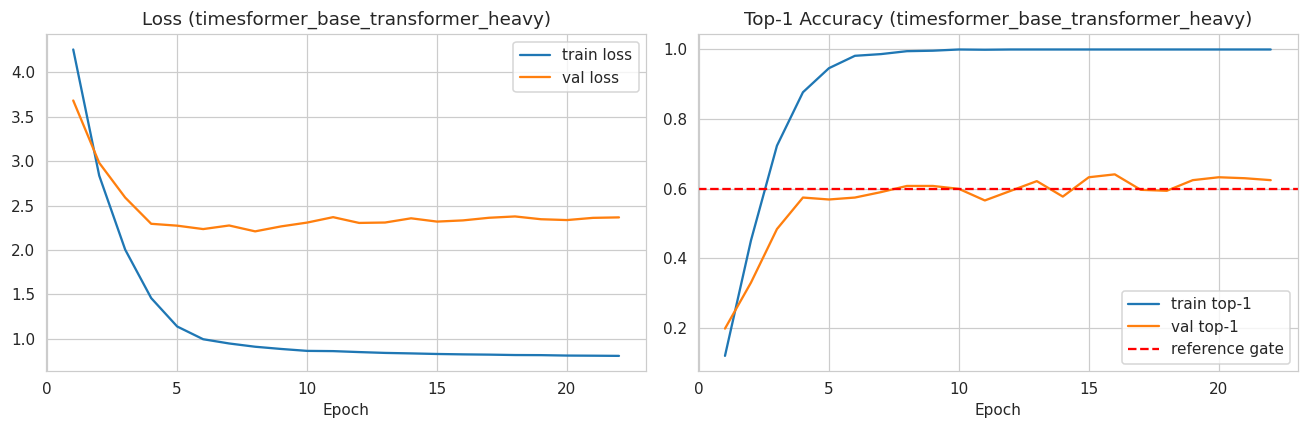

Best-checkpoint validation top-1: 0.641
Reference gate (0.60): reached -- soft reference only, this notebook's primary output is the energy/carbon profile, not chasing this threshold


In [11]:
epochs_ran = [h["epoch"] for h in history]
train_loss = [h["train_loss"] for h in history]
val_loss_curve = [h["val_loss"] for h in history]
train_top1 = [h["train_top1"] for h in history]
val_top1_curve = [h["val_top1"] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_ran, train_loss, label="train loss")
axes[0].plot(epochs_ran, val_loss_curve, label="val loss")
axes[0].set_title(f"Loss ({CONFIG.MODEL_TAG})"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(epochs_ran, train_top1, label="train top-1")
axes[1].plot(epochs_ran, val_top1_curve, label="val top-1")
axes[1].axhline(CONFIG.ACCURACY_GATE_THRESHOLD, color="red", linestyle="--", label="reference gate")
axes[1].set_title(f"Top-1 Accuracy ({CONFIG.MODEL_TAG})"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.savefig(CONFIG.OUTPUT_DIR / f"{CONFIG.MODEL_TAG}_train_val_curves.png", dpi=130, bbox_inches="tight")
plt.show()

best_epoch_val_top1 = best_val_top1
print(f"Best-checkpoint validation top-1: {best_epoch_val_top1:.3f}")
print(f"Reference gate ({CONFIG.ACCURACY_GATE_THRESHOLD:.2f}): "
      f"{'reached' if best_epoch_val_top1 >= CONFIG.ACCURACY_GATE_THRESHOLD else 'not reached'} "
      f"-- soft reference only, this notebook's primary output is the energy/carbon profile, "
      f"not chasing this threshold")


## 9. Test-Set Evaluation & Inference Energy Profiling

Same protocol as notebooks 1-3: one deterministic pass for accuracy,
`CONFIG.INFERENCE_PROFILING_PASSES` repeated passes for a stable energy-per-inference reading.

In [12]:
@torch.no_grad()
def collect_predictions(model, loader, device):
    model.eval()
    all_true, all_pred, all_top5 = [], [], []
    for frames, labels in loader:
        frames = frames.to(device)
        logits = model(frames)
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        top1 = probs.argmax(axis=1)
        k = min(5, NUM_CLASSES)
        top5 = probs.argsort(axis=1)[:, ::-1][:, :k]
        all_true.extend(labels.numpy().tolist())
        all_pred.extend(top1.tolist())
        all_top5.append(top5)
    return {
        "y_true": np.array(all_true),
        "y_pred": np.array(all_pred),
        "top5": np.concatenate(all_top5, axis=0),
    }


# --- Accuracy pass: single, deterministic, this is the number reported for accuracy ---
test_preds = collect_predictions(model, test_loader, CONFIG.DEVICE)
test_top1 = (test_preds["y_true"] == test_preds["y_pred"]).mean()
test_top5 = np.mean([t in top5 for t, top5 in zip(test_preds["y_true"], test_preds["top5"])])
print(f"Test Top-1: {test_top1:.3f} | Test Top-5: {test_top5:.3f} | Test clips: {len(test_dataset)}")

_labels = list(range(NUM_CLASSES))
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    test_preds["y_true"], test_preds["y_pred"], labels=_labels, average="macro", zero_division=0)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    test_preds["y_true"], test_preds["y_pred"], labels=_labels, average="weighted", zero_division=0)
print(f"Macro F1: {macro_f1:.3f} | Weighted F1: {weighted_f1:.3f}")

# --- Energy-instrumented inference passes ---
# A single pass over a few hundred test clips is a short, noisy window for a
# power-sampling tracker like CodeCarbon. CONFIG.INFERENCE_PROFILING_PASSES repeats
# the full test-set pass to get a stabler average energy-per-inference reading.
# These repeated passes are NOT used for the accuracy numbers above (those stay a
# single deterministic pass) -- they exist purely to measure per-inference energy.
# Peak GPU memory and per-clip latency during inference (paper review Minor Issue #10:
# neither was reported anywhere in the original submission).
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats(CONFIG.DEVICE)

inference_energy_per_pass_kwh = []
inference_latency_seconds_per_pass = []
if CODECARBON_AVAILABLE:
    for pass_idx in range(CONFIG.INFERENCE_PROFILING_PASSES):
        tracker = EmissionsTracker(
            project_name=f"{CONFIG.MODEL_TAG}_inference_pass{pass_idx}",
            output_dir=str(CONFIG.OUTPUT_DIR), log_level="error",
            save_to_file=False, allow_multiple_runs=True,
        )
        tracker.start()
        _pass_t0 = time.time()
        with torch.no_grad():
            for frames, _ in test_loader:
                frames = frames.to(CONFIG.DEVICE)
                _ = model(frames)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        inference_latency_seconds_per_pass.append(time.time() - _pass_t0)
        tracker.stop()
        emissions_data = tracker.final_emissions_data
        if emissions_data is not None:
            inference_energy_per_pass_kwh.append(emissions_data.energy_consumed)

PEAK_INFERENCE_GPU_MEMORY_GB = (
    round(torch.cuda.max_memory_allocated(CONFIG.DEVICE) / (1024**3), 3)
    if torch.cuda.is_available() else None
)
LATENCY_MS_PER_CLIP = (
    float(np.mean(inference_latency_seconds_per_pass)) / len(test_dataset) * 1000
    if inference_latency_seconds_per_pass else None
)
print(f"Peak GPU memory during inference: {PEAK_INFERENCE_GPU_MEMORY_GB} GB"
      if PEAK_INFERENCE_GPU_MEMORY_GB is not None else "Peak GPU memory during inference: N/A (no GPU)")
print(f"Mean latency per single-clip inference: {LATENCY_MS_PER_CLIP:.2f} ms"
      if LATENCY_MS_PER_CLIP is not None else "Mean latency per single-clip inference: N/A")

if inference_energy_per_pass_kwh:
    MEAN_INFERENCE_ENERGY_PER_PASS_KWH = float(np.mean(inference_energy_per_pass_kwh))
    ENERGY_PER_CLIP_KWH = MEAN_INFERENCE_ENERGY_PER_PASS_KWH / len(test_dataset)
    print(f"\nMean energy per full test-set pass ({len(test_dataset)} clips): "
          f"{MEAN_INFERENCE_ENERGY_PER_PASS_KWH:.6f} kWh, across {len(inference_energy_per_pass_kwh)} passes")
    print(f"Estimated energy per single-clip inference: {ENERGY_PER_CLIP_KWH * 1e6:.2f} mWh")
else:
    MEAN_INFERENCE_ENERGY_PER_PASS_KWH = None
    ENERGY_PER_CLIP_KWH = None
    print("\nInference energy profiling skipped (codecarbon not installed).")


Test Top-1: 0.609 | Test Top-5: 0.850 | Test clips: 1409
Macro F1: 0.591 | Weighted F1: 0.591
Peak GPU memory during inference: 1.385 GB
Mean latency per single-clip inference: 139.96 ms

Mean energy per full test-set pass (1409 clips): 0.005348 kWh, across 3 passes
Estimated energy per single-clip inference: 3.80 mWh


### 9b. External Accuracy Reference Points (Not Reproduced Locally)

**Paper review Major Issue #3:** this study only compares its own five models against each
other. Without an external reference point, a reader cannot tell whether this notebook's
top-1 accuracy on the 100-class ASL Citizen pilot is competitive, mediocre, or unusually low
for the task -- the accuracy ceiling could reflect task difficulty at this scale just as
easily as an architectural or protocol limitation.

We do **not** reproduce these external numbers in this notebook (different class subsets,
splits, and training budgets make a like-for-like re-run out of scope for a single-model
green-computing unit), but they are recorded here so the number produced above can be read
in context rather than in isolation:

- **Alkhoraif et al. (2026)** report state-of-the-art accuracy on ASL Citizen (among other
  datasets) using a two-stream Swin-Transformer ensemble combining appearance and pose
  modalities -- a substantially heavier, multi-modal pipeline than any single model in this
  family.
- **Brettmann et al. (2025)** report that a VideoMAE-based ViViT variant substantially
  outperforms a traditional CNN baseline on WLASL100, a comparable-scale (100-class)
  word-level sign recognition benchmark.
- **Shawon et al. (2026)** compare VideoMAE, ViViT, and TimeSformer -- the same TimeSformer
  family used as this study's heavy Transformer entry -- on Bangla Sign Language datasets,
  finding video-Transformer accuracy sensitive to dataset size, frame rate, and signer
  variation.

None of these three report training or inference energy alongside their accuracy figures,
which is precisely the gap this five-model family's green-computing instrumentation exists
to fill -- but their accuracy numbers are the closest available external reference for
judging whether this notebook's own top-1 figure is in a reasonable range for a 100-class
word-level sign recognition task. A future revision could re-run one of these external
methods on this exact 100-class split to make the comparison direct rather than contextual.

## 10. Green-Computing Accounting — Carbon, Amortization, Efficiency

Same Eq. (1) / Eq. (2) / amortized-carbon math and constants as notebooks 1-3.

In [13]:
def fmt(value, spec=".4f", suffix=""):
    return "N/A" if value is None else f"{value:{spec}}{suffix}"


GRID_INTENSITY = CONFIG.GRID_CARBON_INTENSITY_KG_PER_KWH  # kg CO2e / kWh -- Eq. (1) in the proposal


def kwh_to_co2_kg(kwh):
    return None if kwh is None else kwh * GRID_INTENSITY


# --- Eq. (1): energy -> carbon ---
train_co2_kg_estimated = kwh_to_co2_kg(TOTAL_TRAIN_ENERGY_KWH)
inference_co2_kg_per_clip = kwh_to_co2_kg(ENERGY_PER_CLIP_KWH)

train_co2_g = None if train_co2_kg_estimated is None else train_co2_kg_estimated * 1000
inference_co2_mg_per_clip = None if inference_co2_kg_per_clip is None else inference_co2_kg_per_clip * 1e6

print("[Eq. 1] Estimated total training CO2e:", fmt(train_co2_g, ".2f", " g"),
      f"(grid intensity assumption: {GRID_INTENSITY} kg/kWh)")
print("[Eq. 1] Estimated CO2e per inference:", fmt(inference_co2_mg_per_clip, ".3f", " mg"))

# --- Faculty feedback: amortized training carbon / expected inference volume ---
# CONFIG.EXPECTED_INFERENCE_VOLUME is a placeholder deployment-scenario assumption
# (see CONFIG comment) -- swap in a properly justified/cited figure before this goes
# in the paper.
amortized_training_co2_per_inference_kg = None
if train_co2_kg_estimated is not None:
    amortized_training_co2_per_inference_kg = train_co2_kg_estimated / CONFIG.EXPECTED_INFERENCE_VOLUME

total_lifecycle_co2_per_inference_kg = None
if amortized_training_co2_per_inference_kg is not None and inference_co2_kg_per_clip is not None:
    total_lifecycle_co2_per_inference_kg = (
        amortized_training_co2_per_inference_kg + inference_co2_kg_per_clip
    )

amortized_mg = None if amortized_training_co2_per_inference_kg is None else amortized_training_co2_per_inference_kg * 1e6
lifecycle_mg = None if total_lifecycle_co2_per_inference_kg is None else total_lifecycle_co2_per_inference_kg * 1e6

print(f"\nAmortized training CO2e per inference "
      f"(assuming {CONFIG.EXPECTED_INFERENCE_VOLUME:,} lifetime inferences):", fmt(amortized_mg, ".4f", " mg"))
print("Total lifecycle CO2e per inference (amortized training + marginal inference):",
      fmt(lifecycle_mg, ".4f", " mg"))

# --- Eq. (2): accuracy-per-carbon efficiency metric ---
def efficiency_metric(accuracy_pct, co2_g):
    if co2_g is None or co2_g == 0:
        return None
    return accuracy_pct / co2_g


eta_train = efficiency_metric(test_top1 * 100, train_co2_g)
lifecycle_co2_g_per_inference = None if lifecycle_mg is None else lifecycle_mg / 1000
eta_lifecycle_per_inference = efficiency_metric(test_top1 * 100, lifecycle_co2_g_per_inference)

print("\n[Eq. 2] eta_acc/carbon (training-total basis):", fmt(eta_train, ".4f", " % per g CO2e"))
print("[Eq. 2] eta_acc/carbon (per-inference lifecycle basis):",
      fmt(eta_lifecycle_per_inference, ".6f", " % per g CO2e"))

# --- Lifecycle sensitivity analysis (paper review Recommended fix: the single 100,000-
# inference deployment-volume assumption was never sensitivity-tested in the original
# submission). Recomputes eta_life at each volume in CONFIG.DEPLOYMENT_VOLUME_SENSITIVITY
# so the model's efficiency ranking can be checked for stability across plausible scales,
# not just trusted at one arbitrary point estimate.
lifecycle_sensitivity = []
for n_inf in CONFIG.DEPLOYMENT_VOLUME_SENSITIVITY:
    amortized_kg_n = None if train_co2_kg_estimated is None else train_co2_kg_estimated / n_inf
    lifecycle_kg_n = None
    if amortized_kg_n is not None and inference_co2_kg_per_clip is not None:
        lifecycle_kg_n = amortized_kg_n + inference_co2_kg_per_clip
    lifecycle_g_n = None if lifecycle_kg_n is None else lifecycle_kg_n * 1000
    eta_life_n = efficiency_metric(test_top1 * 100, lifecycle_g_n)
    lifecycle_sensitivity.append({
        "deployment_volume_inferences": n_inf,
        "lifecycle_co2_mg_per_inference": None if lifecycle_kg_n is None else lifecycle_kg_n * 1e6,
        "eta_lifecycle_pct_per_g_co2e": eta_life_n,
    })

print("\n[Sensitivity] eta_life across deployment-volume assumptions (not just the single",
      f"{CONFIG.EXPECTED_INFERENCE_VOLUME:,}-inference point estimate):")
for row in lifecycle_sensitivity:
    print(f"  N={row['deployment_volume_inferences']:>10,}  "
          f"lifecycle_CO2e/inference={fmt(row['lifecycle_co2_mg_per_inference'], '.4f', ' mg')}  "
          f"eta_life={fmt(row['eta_lifecycle_pct_per_g_co2e'], '.6f', ' %/g CO2e')}")

# --- Parametric deployment-threshold check (paper review Minor Issue #7: the 60% soft
# accuracy reference is author-defined, not externally justified). Reports whether this
# model clears each candidate threshold rather than resting the deployment narrative on
# one unjustified line.
threshold_check = {
    f"clears_{int(t*100)}pct_threshold": bool(test_top1 >= t)
    for t in CONFIG.ACCURACY_GATE_THRESHOLDS_FOR_SENSITIVITY
}
print("\n[Sensitivity] Deployment-threshold check (test_top1 =", f"{test_top1:.3f}):")
for k, v in threshold_check.items():
    print(f"  {k}: {v}")


[Eq. 1] Estimated total training CO2e: 76.37 g (grid intensity assumption: 0.41272 kg/kWh)
[Eq. 1] Estimated CO2e per inference: 1.566 mg

Amortized training CO2e per inference (assuming 100,000 lifetime inferences): 0.7637 mg
Total lifecycle CO2e per inference (amortized training + marginal inference): 2.3302 mg

[Eq. 2] eta_acc/carbon (training-total basis): 0.7973 % per g CO2e
[Eq. 2] eta_acc/carbon (per-inference lifecycle basis): 26132.462292 % per g CO2e

[Sensitivity] eta_life across deployment-volume assumptions (not just the single 100,000-inference point estimate):
  N=    10,000  lifecycle_CO2e/inference=9.2038 mg  eta_life=6616.218630 %/g CO2e
  N=   100,000  lifecycle_CO2e/inference=2.3302 mg  eta_life=26132.462292 %/g CO2e
  N= 1,000,000  lifecycle_CO2e/inference=1.6429 mg  eta_life=37066.049927 %/g CO2e

[Sensitivity] Deployment-threshold check (test_top1 = 0.609):
  clears_50pct_threshold: True
  clears_60pct_threshold: True
  clears_70pct_threshold: False


## 10b. Multi-Seed Repetition for Statistical Validity

Repeats the full train+eval pipeline across `CONFIG.SEEDS` and reports mean +/- SD for every headline metric (paper review Major Issue #2). This is the single most compute-expensive addition in this notebook -- it multiplies total training cost by `len(CONFIG.SEEDS)`, which is itself worth reporting as part of this study's own carbon cost of doing rigorous science.

In [14]:
# --- Multi-seed repetition for statistical validity (paper review Major Issue #2: every
# comparative claim in the original single-run submission rested on n=1 per model, with
# no seeds, no variance, no CI anywhere -- self-disclosed but never fixed). The seed
# CONFIG.SEED run above (Sections 7-9) is reused as the first data point; this cell repeats
# the full train+eval pipeline for every remaining seed in CONFIG.SEEDS and reports
# mean +/- SD for every headline metric, so the model-vs-model rankings in the cross-model
# comparison can finally be checked against run-to-run noise.

MULTI_SEED_RESULTS = [{
    "seed": CONFIG.SEED,
    "test_top1": float(test_top1),
    "test_top5": float(test_top5),
    "best_val_top1": float(best_val_top1),
    "epochs_ran": len(history),
    "total_train_energy_kwh": TOTAL_TRAIN_ENERGY_KWH,
    "total_train_co2_g": train_co2_g,
    "eta_acc_per_carbon_training_basis": eta_train,
    "wall_clock_train_minutes": wall_clock_train_minutes,
    "peak_train_gpu_memory_gb": PEAK_TRAIN_GPU_MEMORY_GB,
}]


def _train_and_evaluate_one_seed(seed):
    """Rebuilds the model from scratch under a fresh seed, retrains it end-to-end with
    the same protocol as the primary run (Section 7), evaluates it, and returns the same
    headline metrics as the primary run's globals -- so it can be folded into
    MULTI_SEED_RESULTS on equal footing."""
    global model, optimizer, scheduler

    seed_everything(seed)
    model = TimeSformerSLRModel(num_classes=NUM_CLASSES).to(CONFIG.DEVICE)
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=CONFIG.LR, weight_decay=CONFIG.WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG.EPOCHS_FULL)

    _best_val_top1 = -float("inf")
    _epochs_without_improvement = 0
    _best_state_dict = None
    _per_epoch_energy_kwh = []
    _epochs_ran = 0

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats(CONFIG.DEVICE)

    _t0 = time.time()
    for epoch in range(1, CONFIG.EPOCHS_FULL + 1):
        tracker = None
        if CODECARBON_AVAILABLE:
            tracker = EmissionsTracker(
                project_name=f"{CONFIG.MODEL_TAG}_seed{seed}_epoch{epoch}",
                output_dir=str(CONFIG.OUTPUT_DIR), log_level="error",
                save_to_file=False, allow_multiple_runs=True,
            )
            tracker.start()

        train_metrics = run_epoch(train_loader, train=True)
        val_metrics = run_epoch(val_loader, train=False)
        scheduler.step()
        _epochs_ran = epoch

        epoch_energy_kwh = None
        if tracker is not None:
            tracker.stop()
            emissions_data = tracker.final_emissions_data
            if emissions_data is not None:
                epoch_energy_kwh = emissions_data.energy_consumed
        if epoch_energy_kwh is not None:
            _per_epoch_energy_kwh.append(epoch_energy_kwh)

        is_best = val_metrics["top1"] > _best_val_top1
        if is_best:
            _best_val_top1 = val_metrics["top1"]
            _epochs_without_improvement = 0
            _best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            _epochs_without_improvement += 1
            if (epoch >= CONFIG.MIN_EPOCHS_BEFORE_STOPPING
                    and _epochs_without_improvement >= CONFIG.EARLY_STOPPING_PATIENCE):
                print(f"  [seed {seed}] early stopping at epoch {epoch}")
                break

    wall_min = (time.time() - _t0) / 60
    if _best_state_dict is not None:
        model.load_state_dict(_best_state_dict)
    model.eval()

    peak_train_mem_gb = (
        round(torch.cuda.max_memory_allocated(CONFIG.DEVICE) / (1024**3), 3)
        if torch.cuda.is_available() else None
    )
    total_train_energy_kwh = sum(_per_epoch_energy_kwh) if _per_epoch_energy_kwh else None

    preds = collect_predictions(model, test_loader, CONFIG.DEVICE)
    seed_test_top1 = float((preds["y_true"] == preds["y_pred"]).mean())
    seed_test_top5 = float(np.mean([t in top5 for t, top5 in zip(preds["y_true"], preds["top5"])]))

    train_co2_kg_seed = kwh_to_co2_kg(total_train_energy_kwh)
    train_co2_g_seed = None if train_co2_kg_seed is None else train_co2_kg_seed * 1000
    eta_train_seed = efficiency_metric(seed_test_top1 * 100, train_co2_g_seed)

    print(f"  [seed {seed}] test_top1={seed_test_top1:.3f} epochs={_epochs_ran} "
          f"train_co2_g={fmt(train_co2_g_seed, '.2f')} wall_min={wall_min:.1f}")

    return {
        "seed": seed,
        "test_top1": seed_test_top1,
        "test_top5": seed_test_top5,
        "best_val_top1": float(_best_val_top1),
        "epochs_ran": _epochs_ran,
        "total_train_energy_kwh": total_train_energy_kwh,
        "total_train_co2_g": train_co2_g_seed,
        "eta_acc_per_carbon_training_basis": eta_train_seed,
        "wall_clock_train_minutes": wall_min,
        "peak_train_gpu_memory_gb": peak_train_mem_gb,
    }


for _seed in CONFIG.SEEDS:
    if _seed == CONFIG.SEED:
        continue
    print(f"\n=== Repeating full train+eval for seed={_seed} ===")
    MULTI_SEED_RESULTS.append(_train_and_evaluate_one_seed(_seed))

# --- Aggregate mean +/- SD across all collected seeds ---
import statistics as _stats


def _mean_sd(metric_key):
    vals = [r[metric_key] for r in MULTI_SEED_RESULTS if r.get(metric_key) is not None]
    if not vals:
        return None, None
    if len(vals) == 1:
        return vals[0], 0.0
    return _stats.mean(vals), _stats.stdev(vals)


MULTI_SEED_SUMMARY = {"n_seeds": len(MULTI_SEED_RESULTS), "seeds": [r["seed"] for r in MULTI_SEED_RESULTS]}
for _k in ["test_top1", "test_top5", "total_train_co2_g", "eta_acc_per_carbon_training_basis",
           "total_train_energy_kwh", "wall_clock_train_minutes"]:
    _m, _s = _mean_sd(_k)
    MULTI_SEED_SUMMARY[f"{_k}_mean"] = _m
    MULTI_SEED_SUMMARY[f"{_k}_std"] = _s

print(f"\n=== Multi-seed summary (n={MULTI_SEED_SUMMARY['n_seeds']} seeds: {MULTI_SEED_SUMMARY['seeds']}) ===")
for _k, _v in MULTI_SEED_SUMMARY.items():
    if _k in ("n_seeds", "seeds"):
        continue
    print(f"  {_k}: {fmt(_v, '.4f')}")



=== Repeating full train+eval for seed=123 ===


Loading weights:   0%|          | 0/247 [00:00<?, ?it/s]

TimesformerModel LOAD REPORT from: facebook/timesformer-base-finetuned-k400
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [seed 123] early stopping at epoch 28
  [seed 123] test_top1=0.605 epochs=28 train_co2_g=97.26 wall_min=146.7

=== Repeating full train+eval for seed=2024 ===


Loading weights:   0%|          | 0/247 [00:00<?, ?it/s]

TimesformerModel LOAD REPORT from: facebook/timesformer-base-finetuned-k400
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [seed 2024] early stopping at epoch 16
  [seed 2024] test_top1=0.583 epochs=16 train_co2_g=55.57 wall_min=83.8

=== Multi-seed summary (n=3 seeds: [42, 123, 2024]) ===
  test_top1_mean: 0.5990
  test_top1_std: 0.0137
  test_top5_mean: 0.8472
  test_top5_std: 0.0025
  total_train_co2_g_mean: 76.4007
  total_train_co2_g_std: 20.8411
  eta_acc_per_carbon_training_basis_mean: 0.8229
  eta_acc_per_carbon_training_basis_std: 0.2152
  total_train_energy_kwh_mean: 0.1851
  total_train_energy_kwh_std: 0.0505
  wall_clock_train_minutes_mean: 115.2526
  wall_clock_train_minutes_std: 31.4281


## 11. Model Card Export

Saves `green_metrics_timesformer_base_transformer_heavy.json`, matching the earlier notebooks'
schema plus `frame_count_used` and `gflops_is_lower_bound`.

In [15]:
model_card = {
    "model_tag": CONFIG.MODEL_TAG,
    "architecture_family": "Transformer (heavy, divided space-time attention)",
    "backbone": "TimeSformer-base, Kinetics-400-pretrained (facebook/timesformer-base-finetuned-k400)",
    "num_classes": NUM_CLASSES,
    "top_k_classes_config": CONFIG.TOP_K_CLASSES,
    "frame_count_cached": CONFIG.FRAME_COUNT,
    "frame_count_used": CONFIG.TIMESFORMER_NUM_FRAMES,
    "image_size": CONFIG.IMAGE_SIZE,
    "params_total": n_params_total,
    "params_trainable": n_params_trainable,
    "gflops_per_inference": gflops_per_inference,
    "gflops_is_lower_bound": True,
    "test_top1": float(test_top1),
    "test_top5": float(test_top5),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "best_val_top1": float(best_val_top1),
    "epochs_ran": len(history),
    "wall_clock_train_minutes": wall_clock_train_minutes,
    "total_train_energy_kwh": TOTAL_TRAIN_ENERGY_KWH,
    "grid_carbon_intensity_kg_per_kwh": GRID_INTENSITY,
    "total_train_co2_g": train_co2_g,
    "energy_per_inference_kwh": ENERGY_PER_CLIP_KWH,
    "co2_per_inference_mg": inference_co2_mg_per_clip,
    "expected_inference_volume_assumption": CONFIG.EXPECTED_INFERENCE_VOLUME,
    "amortized_train_co2_per_inference_mg": amortized_mg,
    "total_lifecycle_co2_per_inference_mg": lifecycle_mg,
    "eta_acc_per_carbon_training_basis": eta_train,
    "eta_acc_per_carbon_lifecycle_basis": eta_lifecycle_per_inference,

    # --- Fields added in response to the paper review's Major/Minor issues ---
    "hardware_software_environment": HARDWARE_INFO,
    "signer_independence_report": SIGNER_INDEPENDENCE_REPORT,
    "peak_train_gpu_memory_gb": PEAK_TRAIN_GPU_MEMORY_GB,
    "peak_inference_gpu_memory_gb": PEAK_INFERENCE_GPU_MEMORY_GB,
    "latency_ms_per_clip_inference": LATENCY_MS_PER_CLIP,
    "lifecycle_carbon_sensitivity": lifecycle_sensitivity,
    "deployment_threshold_sensitivity": threshold_check,
    "multi_seed_results": MULTI_SEED_RESULTS,
    "multi_seed_summary": MULTI_SEED_SUMMARY,
    # Multi-seed mean/SD are the headline figures for cross-model comparison going
    # forward (paper review Major Issue #2) -- single-seed fields above are kept for
    # backward compatibility with the original schema, not as the primary result.
    "test_top1_mean": MULTI_SEED_SUMMARY.get("test_top1_mean"),
    "test_top1_std": MULTI_SEED_SUMMARY.get("test_top1_std"),
    "total_train_co2_g_mean": MULTI_SEED_SUMMARY.get("total_train_co2_g_mean"),
    "total_train_co2_g_std": MULTI_SEED_SUMMARY.get("total_train_co2_g_std"),
    "eta_acc_per_carbon_training_basis_mean": MULTI_SEED_SUMMARY.get("eta_acc_per_carbon_training_basis_mean"),
    "eta_acc_per_carbon_training_basis_std": MULTI_SEED_SUMMARY.get("eta_acc_per_carbon_training_basis_std"),
}

model_card_path = CONFIG.OUTPUT_DIR / f"green_metrics_{CONFIG.MODEL_TAG}.json"
with open(model_card_path, "w") as f:
    json.dump(model_card, f, indent=2)

print(f"Model card saved to: {model_card_path}")
print("Note two fields specific to this notebook: 'frame_count_used' differs from "
      "'frame_count_cached' (8 vs 16, see Section 2), and 'gflops_is_lower_bound' is "
      "True (see Section 6) -- both matter when this JSON joins the other four.")
display(pd.DataFrame([model_card]).T.rename(columns={0: "value"}))


Model card saved to: /kaggle/working/green_report_timesformer_base_transformer_heavy/green_metrics_timesformer_base_transformer_heavy.json
Note two fields specific to this notebook: 'frame_count_used' differs from 'frame_count_cached' (8 vs 16, see Section 2), and 'gflops_is_lower_bound' is True (see Section 6) -- both matter when this JSON joins the other four.


,value
model_tag,timesformer_base_transformer_heavy
architecture_family,"Transformer (heavy, divided space-time attention)"
backbone,"TimeSformer-base, Kinetics-400-pretrained (fac..."
num_classes,100
top_k_classes_config,100
frame_count_cached,16
frame_count_used,8
image_size,224
params_total,121335652
params_trainable,20163172


## 12. Notes for the Paper / Next Steps

- **Both architecture families are now complete:** CNN (MobileNetV3-Small light / ResNet-50
  heavy) and Transformer (ViViT-Lite light / TimeSformer heavy). Four `green_metrics_*.json`
  files exist after this notebook runs — enough for the paper's core RQ1/RQ2 comparison and a
  first pass at the accuracy-vs-carbon Pareto plot (Section V-D of the proposal), even before
  TinyMSLR.
- **One more model left:** TinyMSLR (distilled hybrid), per the Nature paper faculty cited in
  the feedback. That one needs its source paper worked through before implementation — it's not
  a variation on any of the four notebooks so far.
- **A genuine open question for the paper, not a foregone conclusion:** does TimeSformer's
  extra parameter count and attention density over ViViT-Lite buy proportionally more accuracy,
  or does the Transformer family show diminishing accuracy-per-carbon returns the same way (or
  differently from) the CNN family's MobileNetV3-to-ResNet-50 jump? That comparison is only
  answerable once both notebooks have actually run.
- Numbers from this notebook are real once you run it on Kaggle — nothing above is pre-filled or
  asserted in advance.